# SANOS + EKF Evaluation

Online SANOS EKF for a single expiry: calls only.  
Sections: data loading → fit → in-sample → OOS → density diagnostics → state evolution.

In [22]:
import os
import sys
from datetime import date

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import norm as sp_norm

project_root = "/Users/elie/Documents/GitHub/quant_data/"
kf_dir = os.path.join(project_root, "personal", "Kalman_filter_spline")
for p in [project_root, kf_dir]:
    if p not in sys.path:
        sys.path.insert(0, p)

os.environ.setdefault("QUANTDATA_RAW_DATA", "/quantdata/raw")

from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from personal.SANOS_KF.sanos_kf import SanosKFConfig, _invert_iv_vec, _project_q, run_sanos_kf
from quantdata.massive.client import MassiveClient

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Config

In [ ]:
TICKER = "SPY"
TRADE_DATE = date(2024, 1, 3)
MIN_TRADES = 100

## Load data

In [ ]:
df_tickers = pl.read_csv(os.path.join(project_root, "personal", "spy_options_tickers.csv"))

client = MassiveClient()
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

df_quotes_all, df_trades_all = build_iv_observations(
    df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES
)

print(f"quotes: {len(df_quotes_all):,}   trades: {len(df_trades_all):,}")
print("quote columns:", df_quotes_all.columns)

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
quotes: 2,115,510   trades: 74,099
quote columns: ['ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'R_iv', 'bid_price', 'ask_price', 'forward', 'discount_factor']


In [24]:
df_quotes_all

ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,null
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43,null
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,null
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,null
…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,469.0,true,-0.000117,0.005447,0.134535,0.134132,0.134856,1.3110e-7,1.88,1.89,469.055,1.0
2024-01-03 16:14:59.884593152 EST,474.0,false,0.010487,0.005447,0.138451,0.132675,0.144803,0.000037,5.28,5.38,469.055,1.0
2024-01-03 16:14:59.884598272 EST,472.0,false,0.006259,0.005447,0.13324,0.131454,0.136743,0.000007,3.66,3.72,469.055,1.0


In [31]:
# Initialize sigma_star from first ATM quote
ks = df_quotes_all["strike"] / df_quotes_all["forward"] - 1.0
bids = df_quotes_all["bid_price"]
asks = df_quotes_all["ask_price"]
fwds = df_quotes_all["forward"]
dfs = df_quotes_all["discount_factor"]
Ts = df_quotes_all["T"]


atm_mask = np.abs(ks) < 0.01
if atm_mask.any():
    first_atm_idx = np.where(atm_mask)[0][0]
    print(first_atm_idx)
    mid_atm = (bids[int(first_atm_idx)] + asks[int(first_atm_idx)]) / 2.0
    scale_atm = fwds[int(first_atm_idx)]
    mid_norm_atm = mid_atm / scale_atm
    T_atm = Ts[int(first_atm_idx)]
    atm_ivs = _invert_iv_vec(
        np.array([mid_norm_atm]), np.array([ks[int(first_atm_idx)]]), np.array([T_atm])
    )
    if np.isfinite(atm_ivs[0]) and atm_ivs[0] > 0:
        sigma_star_init = atm_ivs[0]

1


In [32]:
sigma_star_init

np.float64(0.16645308874867584)

## Config

In [122]:
cfg = SanosKFConfig(
    n_anchors=20,
    k_min=-0.20,
    k_max=0.15,
    sigma_star_init=0.16,
    Sigma_init=0.0025,
    Q_scale_dlv=1e-3,  # variance per trading day for log-DLV
    P0_scale=1e-1,  # was 1.0 — reduced to prevent initial gain explosion
    calls_only=True,
)

anchor_ks = np.linspace(cfg.k_min, cfg.k_max, cfg.n_anchors)
anchor_K = np.exp(anchor_ks)

In [123]:
# Pick the expiry with the most trades (single-expiry scope)
# exp_counts = (
#     df_trades_all
#     .group_by("T")
#     .agg(pl.len().alias("n"))
#     .sort("n", descending=True)
# )
# EXPIRY_T = exp_counts["T"][0]
# print(f"Selected expiry T = {EXPIRY_T:.6f} yr  ({exp_counts['n'][0]} trades)")

# df_quotes_exp = df_quotes_all.filter(pl.col("T") == EXPIRY_T)
# df_trades_exp = df_trades_all.filter(pl.col("T") == EXPIRY_T)
# print(f"Expiry quotes: {len(df_quotes_exp):,}   trades: {len(df_trades_exp):,}")
df_quotes_exp = df_quotes_all.drop("discount_factor")
df_trades_exp = df_trades_all.drop("discount_factor")

In [124]:
df_quotes_all

ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,null
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43,null
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,null
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,null
…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,469.0,true,-0.000117,0.005447,0.134535,0.134132,0.134856,1.3110e-7,1.88,1.89,469.055,1.0
2024-01-03 16:14:59.884593152 EST,474.0,false,0.010487,0.005447,0.138451,0.132675,0.144803,0.000037,5.28,5.38,469.055,1.0
2024-01-03 16:14:59.884598272 EST,472.0,false,0.006259,0.005447,0.13324,0.131454,0.136743,0.000007,3.66,3.72,469.055,1.0


In [125]:
df_quotes_all.filter(pl.col("is_call") == True).select(pl.col("strike")).unique()

strike
f64
480.0
469.0
473.0
477.0
466.0
…
479.0
472.0
465.0


## Run SANOS EKF

In [126]:
# Data-driven anchors: quantiles of observed log-moneyness
ks_obs = df_quotes_exp.filter(pl.col("is_call")).get_column("log_moneyness").to_numpy()

anchor_ks = np.quantile(ks_obs, np.linspace(0, 1, cfg.n_anchors))

In [127]:
anchor_ks

array([-0.03776687, -0.01090206, -0.00948179, -0.00825281, -0.00720416,
       -0.00617316, -0.00510253, -0.00385662, -0.00247566, -0.00129703,
        0.00012366,  0.00162015,  0.00320219,  0.00502317,  0.0072201 ,
        0.00913148,  0.01087306,  0.01294051,  0.01584665,  0.02409238])

In [128]:
df_q, df_t, df_state = run_sanos_kf(
    df_quotes_exp, df_trades_exp, cfg, return_state=True, anchor_ks=anchor_ks
)

print("quote result columns :", df_q.columns)
print("trade result columns :", df_t.columns)
print(f"Finite model prices  : {df_q['sanos_kf_price'].is_finite().sum()}/{len(df_q)}")
print(f"Finite model IVs     : {df_q['sanos_kf_iv'].is_finite().sum()}/{len(df_q)}")
print(f"Finite trade matches : {df_t['sanos_kf_matched'].is_finite().sum()}/{len(df_t)}")

quote result columns : ['ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'R_iv', 'bid_price', 'ask_price', 'forward', 'sanos_kf_price', 'sanos_kf_iv']
trade result columns : ['ts_ns', 'quote_ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'bid_price', 'ask_price', 'forward', 'ts_ns_right', 'sanos_kf_matched', 'trade_residual']
Finite model prices  : 956399/2115510
Finite model IVs     : 942495/2115510
Finite trade matches : 73830/74099


In [129]:
# df_q, df_t, df_state = run_sanos_kf(df_quotes_exp, df_trades_exp, cfg, return_state=True)

# print("quote result columns :", df_q.columns)
# print("trade result columns :", df_t.columns)
# print(f"Finite model prices  : {df_q['sanos_kf_price'].is_finite().sum()}/{len(df_q)}")
# print(f"Finite model IVs     : {df_q['sanos_kf_iv'].is_finite().sum()}/{len(df_q)}")
# print(f"Finite trade matches : {df_t['sanos_kf_matched'].is_finite().sum()}/{len(df_t)}")

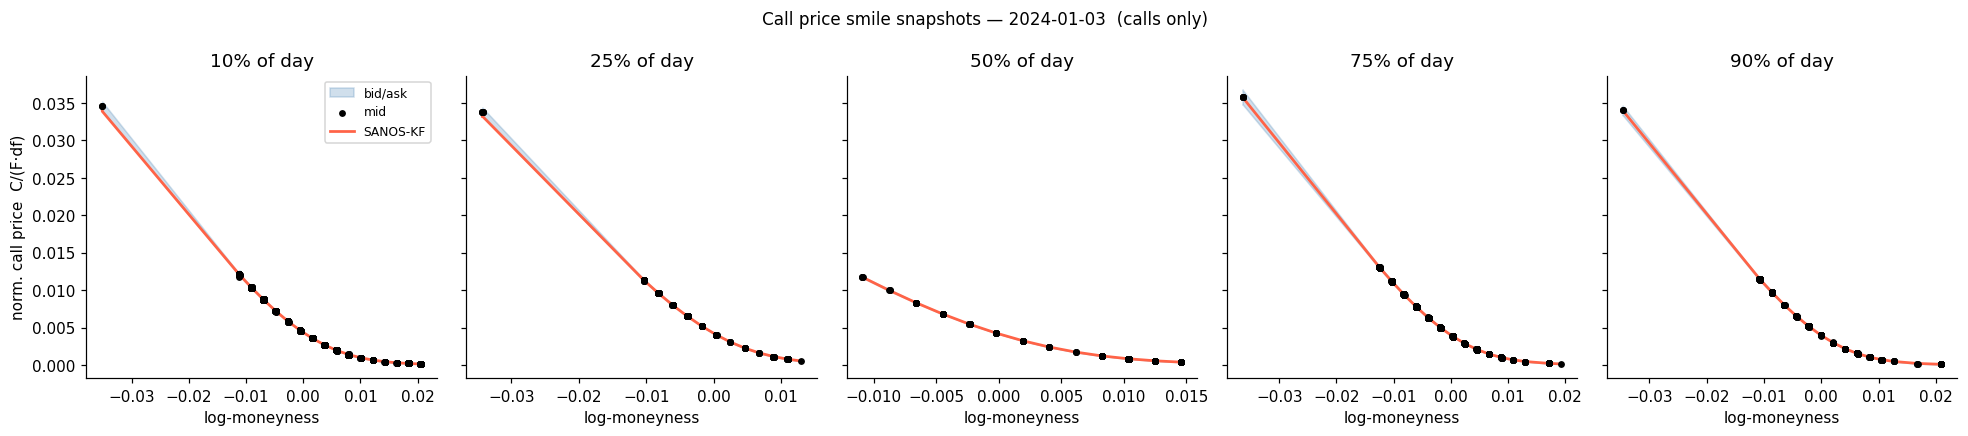

In [130]:
# Use call quotes with finite model price, in the anchor range
has_df_col = "discount_factor" in df_q.columns

df_calls = df_q.filter(
    pl.col("is_call")
    & pl.col("sanos_kf_price").is_finite()
    & (pl.col("log_moneyness") >= cfg.k_min)
    & (pl.col("log_moneyness") <= cfg.k_max)
).sort("ts_ns")

# Normalized market prices: C_norm = price / (F * df)
scale = df_calls["forward"] * (df_calls["discount_factor"] if has_df_col else pl.lit(1.0))
df_calls = df_calls.with_columns(
    [
        (pl.col("bid_price") / scale).alias("bid_price_norm"),
        (pl.col("ask_price") / scale).alias("ask_price_norm"),
        ((pl.col("bid_price") + pl.col("ask_price")) / 2.0 / scale).alias("mid_price_norm"),
    ]
)

ts_vals = df_calls["ts_ns"].cast(pl.Int64).to_numpy()
ts_min, ts_max = ts_vals.min(), ts_vals.max()
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90]
snap_ts = [int(ts_min + p * (ts_max - ts_min)) for p in percentiles]

WINDOW_NS = 5 * int(1e9)  # 5-second snapshot window

fig, axes = plt.subplots(1, len(percentiles), figsize=(18, 4), sharey=True)
for ax, ts_snap, pct in zip(axes, snap_ts, percentiles):
    mask = np.abs(ts_vals - ts_snap) < WINDOW_NS
    df_snap = df_calls.filter(pl.Series(mask))
    if df_snap.is_empty():
        ax.set_title(f"{pct:.0%}")
        continue

    ks = df_snap["log_moneyness"].to_numpy()
    mid = df_snap["mid_price_norm"].to_numpy()
    bid = df_snap["bid_price_norm"].to_numpy()
    ask = df_snap["ask_price_norm"].to_numpy()
    mdl = df_snap["sanos_kf_price"].to_numpy()

    order = np.argsort(ks)
    ax.fill_between(
        ks[order], bid[order], ask[order], alpha=0.25, color="steelblue", label="bid/ask"
    )
    ax.scatter(ks, mid, s=12, color="black", zorder=3, label="mid")
    ax.plot(ks[order], mdl[order], color="tomato", lw=1.8, label="SANOS-KF")
    ax.set_title(f"{pct:.0%} of day")
    ax.set_xlabel("log-moneyness")
    if ax is axes[0]:
        ax.set_ylabel("norm. call price  C/(F·df)")
        ax.legend(fontsize=8)

fig.suptitle(f"Call price smile snapshots — {TRADE_DATE}  (calls only)", fontsize=11)
plt.tight_layout()
plt.show()

---
## Section 1 — In-Sample Fit

### 1a. IV smile snapshots at 5 intraday percentiles

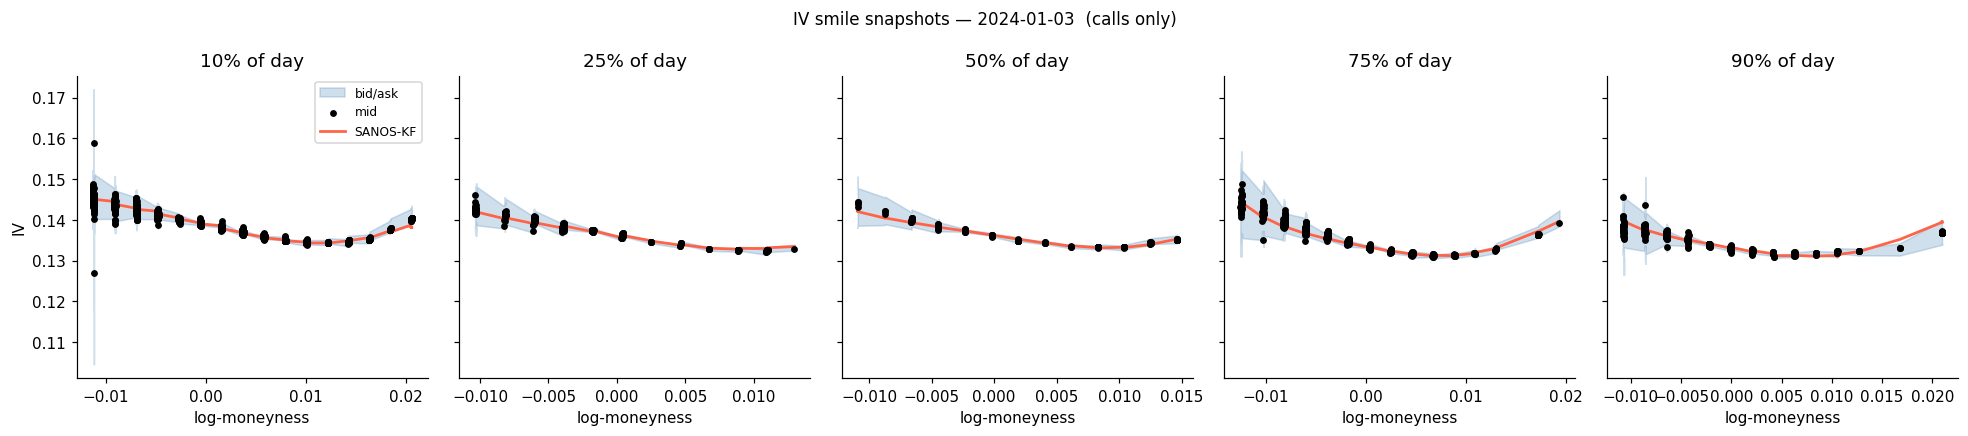

In [131]:
# Use call quotes with finite model IV, in the anchor range
df_calls = df_q.filter(
    pl.col("is_call")
    & pl.col("sanos_kf_iv").is_finite()
    & pl.col("observed_iv").is_finite()
    & (pl.col("log_moneyness") >= cfg.k_min)
    & (pl.col("log_moneyness") <= cfg.k_max)
).sort("ts_ns")

ts_vals = df_calls["ts_ns"].cast(pl.Int64).to_numpy()
ts_min, ts_max = ts_vals.min(), ts_vals.max()
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90]
snap_ts = [int(ts_min + p * (ts_max - ts_min)) for p in percentiles]

# For each snapshot: find the nearest quote bundle (within 5s window)
WINDOW_NS = 5 * int(1e9)

fig, axes = plt.subplots(1, len(percentiles), figsize=(18, 4), sharey=True)
for ax, ts_snap, pct in zip(axes, snap_ts, percentiles):
    mask = np.abs(ts_vals - ts_snap) < WINDOW_NS
    df_snap = df_calls.filter(pl.Series(mask))
    if df_snap.is_empty():
        ax.set_title(f"{pct:.0%}")
        continue
    ks = df_snap["log_moneyness"].to_numpy()
    mid = df_snap["observed_iv"].to_numpy()
    bid = df_snap["bid_iv"].to_numpy()
    ask = df_snap["ask_iv"].to_numpy()
    mdl = df_snap["sanos_kf_iv"].to_numpy()

    order = np.argsort(ks)
    ax.fill_between(
        ks[order], bid[order], ask[order], alpha=0.25, color="steelblue", label="bid/ask"
    )
    ax.scatter(ks, mid, s=12, color="black", zorder=3, label="mid")
    ax.plot(ks[order], mdl[order], color="tomato", lw=1.8, label="SANOS-KF")
    ax.set_title(f"{pct:.0%} of day")
    ax.set_xlabel("log-moneyness")
    if ax is axes[0]:
        ax.set_ylabel("IV")
        ax.legend(fontsize=8)

fig.suptitle(f"IV smile snapshots — {TRADE_DATE}  (calls only)", fontsize=11)
plt.tight_layout()
plt.show()

### 1b. Innovation time series

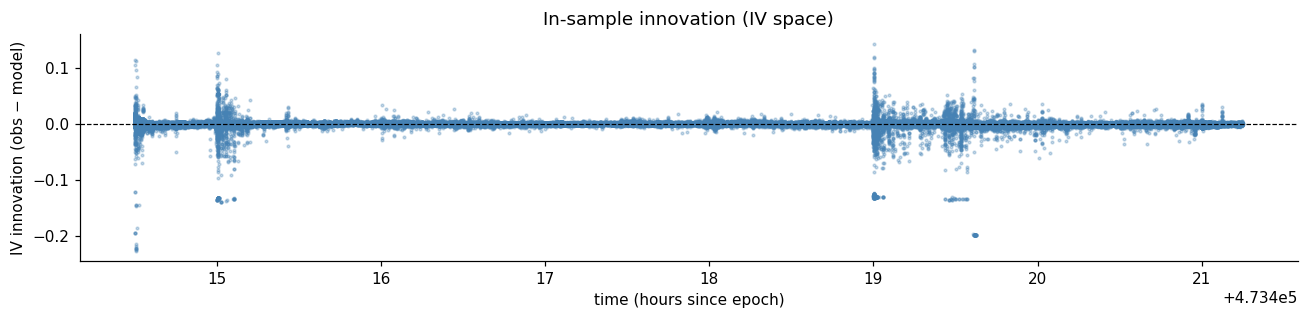

Innovation  mean=-0.0000  std=0.0030


In [132]:
# Innovation = observed_iv - sanos_kf_iv (IV space proxy)
df_innov = df_calls.with_columns(
    (pl.col("observed_iv") - pl.col("sanos_kf_iv")).alias("innov")
).filter(pl.col("innov").is_finite())

ts_h = df_innov["ts_ns"].cast(pl.Int64).to_numpy() / 1e9 / 3600  # hours
innov = df_innov["innov"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 3))
ax.scatter(ts_h, innov, s=3, alpha=0.3, color="steelblue")
ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("IV innovation (obs − model)")
ax.set_title("In-sample innovation (IV space)")
plt.tight_layout()
plt.show()

print(f"Innovation  mean={innov.mean():.4f}  std={innov.std():.4f}")

### 1c. % inside bid-ask band (rolling 1-min window)

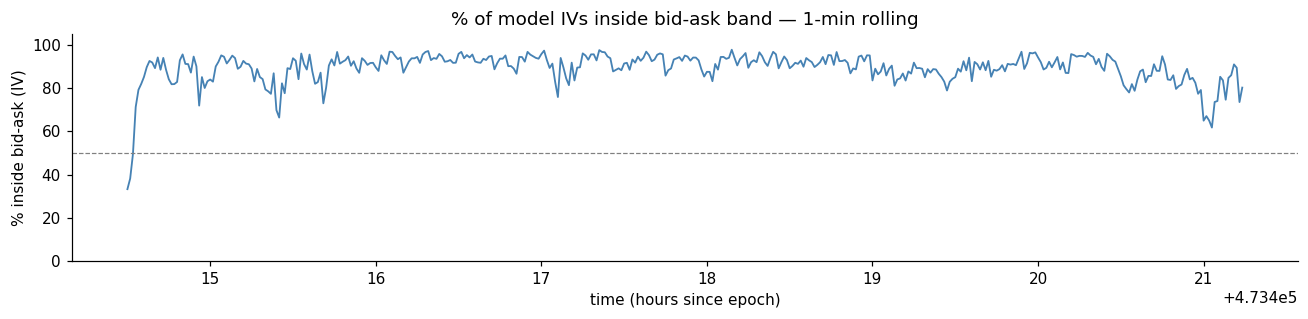

Overall % inside: 88.3%


In [133]:
df_inside = df_calls.with_columns(
    ((pl.col("sanos_kf_iv") >= pl.col("bid_iv")) & (pl.col("sanos_kf_iv") <= pl.col("ask_iv")))
    .cast(pl.Float64)
    .alias("inside")
).filter(pl.col("bid_iv").is_finite() & pl.col("ask_iv").is_finite())

# Bin by 1-minute buckets
BUCKET_NS = int(60e9)
df_rolling = (
    df_inside.with_columns(
        (pl.col("ts_ns").cast(pl.Int64) // BUCKET_NS * BUCKET_NS).alias("bucket")
    )
    .group_by("bucket")
    .agg(pl.col("inside").mean().alias("pct_inside"))
    .sort("bucket")
)

t_buckets = df_rolling["bucket"].to_numpy() / 1e9 / 3600
pct = df_rolling["pct_inside"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_buckets, pct * 100, color="steelblue", lw=1.2)
ax.axhline(50, color="gray", lw=0.8, ls="--")
ax.set_ylim(0, 105)
ax.set_ylabel("% inside bid-ask (IV)")
ax.set_xlabel("time (hours since epoch)")
ax.set_title("% of model IVs inside bid-ask band — 1-min rolling")
plt.tight_layout()
plt.show()

print(f"Overall % inside: {df_inside['inside'].mean() * 100:.1f}%")

---
## Section 2 — OOS Trade Evaluation

### 2a. Trade residual histogram

Trades: 73,830   RMSE=0.0028   Bias=0.0002   MAE=0.0010  (IV units)


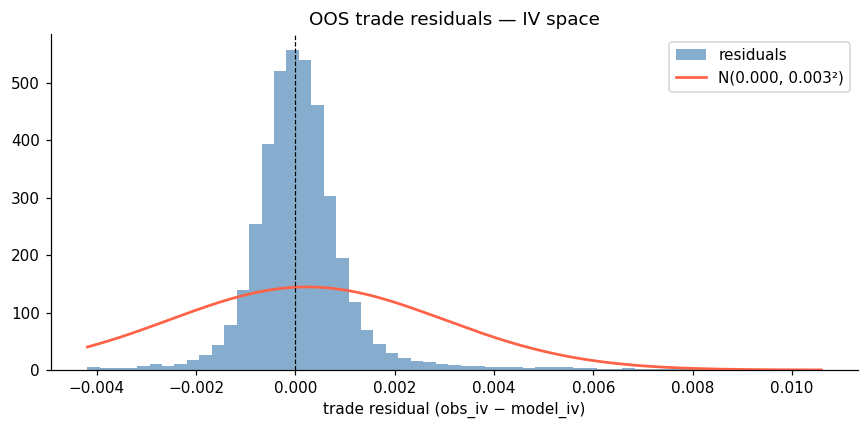

In [134]:
df_tc = df_t.filter(pl.col("trade_residual").is_finite() & pl.col("sanos_kf_matched").is_finite())
resid = df_tc["trade_residual"].to_numpy()

rmse = np.sqrt(np.mean(resid**2))
bias = np.mean(resid)
mae = np.mean(np.abs(resid))
print(f"Trades: {len(resid):,}   RMSE={rmse:.4f}   Bias={bias:.4f}   MAE={mae:.4f}  (IV units)")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(np.percentile(resid, 1), np.percentile(resid, 99), 60)
ax.hist(resid, bins=bins, density=True, alpha=0.65, color="steelblue", label="residuals")

# Gaussian overlay
xg = np.linspace(bins[0], bins[-1], 200)
ax.plot(
    xg, sp_norm.pdf(xg, bias, rmse), color="tomato", lw=1.8, label=f"N({bias:.3f}, {rmse:.3f}²)"
)
ax.axvline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("trade residual (obs_iv − model_iv)")
ax.set_title("OOS trade residuals — IV space")
ax.legend()
plt.tight_layout()
plt.show()

### 2b. Residual vs log-moneyness

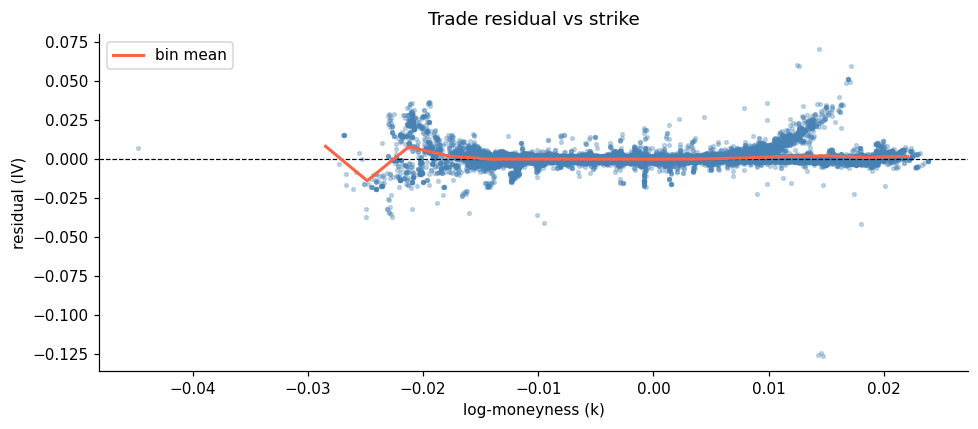

In [135]:
ks_t = df_tc["log_moneyness"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(ks_t, resid, s=6, alpha=0.3, color="steelblue")
ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("log-moneyness (k)")
ax.set_ylabel("residual (IV)")
ax.set_title("Trade residual vs strike")

# Lowess-style bin average
bins_k = np.linspace(ks_t.min(), ks_t.max(), 20)
idx = np.digitize(ks_t, bins_k)
bin_means = [
    resid[idx == i].mean() if (idx == i).sum() > 0 else np.nan for i in range(1, len(bins_k))
]
ax.plot(0.5 * (bins_k[:-1] + bins_k[1:]), bin_means, color="tomato", lw=2, label="bin mean")
ax.legend()
plt.tight_layout()
plt.show()

### 2c. Rolling RMSE over time

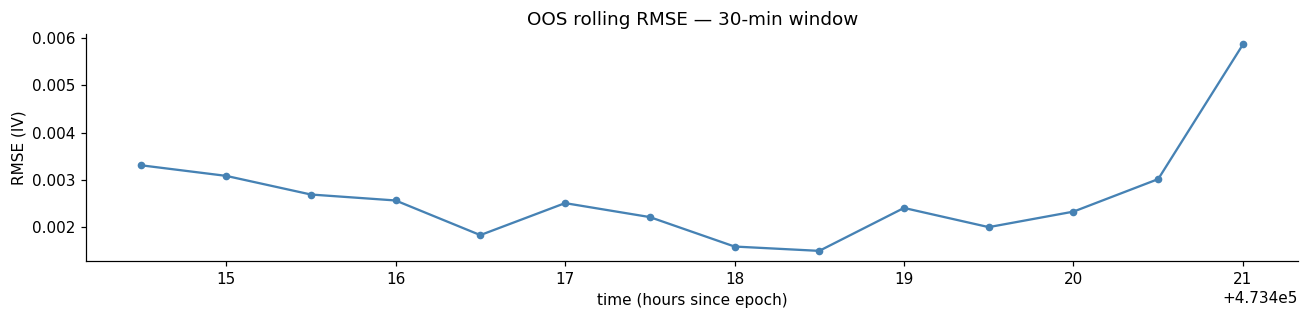

In [136]:
ROLL_NS = int(30 * 60e9)  # 30 min

ts_t = df_tc["ts_ns"].cast(pl.Int64).to_numpy()
ts_buckets_t = (ts_t // ROLL_NS) * ROLL_NS

df_roll_t = (
    df_tc.with_columns((pl.col("ts_ns").cast(pl.Int64) // ROLL_NS * ROLL_NS).alias("bucket"))
    .group_by("bucket")
    .agg(
        (pl.col("trade_residual") ** 2).mean().sqrt().alias("rmse"),
        pl.len().alias("n"),
    )
    .sort("bucket")
    .filter(pl.col("n") >= 3)
)

t_roll = df_roll_t["bucket"].to_numpy() / 1e9 / 3600
rmse_roll = df_roll_t["rmse"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_roll, rmse_roll, color="steelblue", lw=1.5, marker="o", ms=4)
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("RMSE (IV)")
ax.set_title("OOS rolling RMSE — 30-min window")
plt.tight_layout()
plt.show()

n_a = len(anchor_ks)

# State matrix: shape (N_quotes, n_a+1)
x_cols = [f"x_{j}" for j in range(n_a + 1)]
X = df_state.select(x_cols).to_numpy()  # (N, n_a+1)

# Projection matrix (for martingale correction)
A = np.stack([np.ones(n_a), anchor_K])  # (2, n_a)
AAt = A @ A.T  # (2, 2)
b = np.array([1.0, 1.0])

neg_mass = np.full(len(X), np.nan)
entropy = np.full(len(X), np.nan)
bdy_mass = np.full(len(X), np.nan)
mart_resid = np.full(len(X), np.nan)
Q_arr = np.full((len(X), n_a), np.nan)  # projected q at each step

for i, x in enumerate(X):
    if not np.isfinite(x).all():
        continue
    Sigma = np.exp(x[:n_a])
    q_raw = (1.0 / n_a) / (1.0 + Sigma)

    # Martingale correction (before clip)
    residual = A @ q_raw - b
    correction = A.T @ np.linalg.solve(AAt, residual)
    q_before = q_raw - correction

    neg_mass[i] = np.maximum(0, -q_before).sum()

    q_proj = _project_q(q_raw, anchor_K)
    Q_arr[i] = q_proj

    qp = np.maximum(q_proj, 1e-15)
    entropy[i] = -np.sum(qp * np.log(qp))
    bdy_mass[i] = q_proj[0] + q_proj[-1]
    mart_resid[i] = abs(np.dot(q_proj, anchor_K) - 1.0)

ts_state = df_state["ts_ns"].cast(pl.Int64).to_numpy() / 1e9 / 3600
print(f"Negative mass  mean={np.nanmean(neg_mass):.4f}  max={np.nanmax(neg_mass):.4f}")
print(f"Boundary mass  mean={np.nanmean(bdy_mass):.4f}")
print(f"Martingale resid  mean={np.nanmean(mart_resid):.2e}  max={np.nanmax(mart_resid):.2e}")

In [137]:
n_a = cfg.n_anchors

# State matrix: shape (N_quotes, n_a+1)
x_cols = [f"x_{j}" for j in range(n_a + 1)]
X = df_state.select(x_cols).to_numpy()  # (N, n_a+1)

# Projection matrix (for martingale correction)
A = np.stack([np.ones(n_a), anchor_K])  # (2, n_a)
AAt = A @ A.T  # (2, 2)
b = np.array([1.0, 1.0])

neg_mass = np.full(len(X), np.nan)
entropy = np.full(len(X), np.nan)
bdy_mass = np.full(len(X), np.nan)
mart_resid = np.full(len(X), np.nan)
Q_arr = np.full((len(X), n_a), np.nan)  # projected q at each step

for i, x in enumerate(X):
    if not np.isfinite(x).all():
        continue
    Sigma = np.exp(x[:n_a])
    q_raw = (1.0 / n_a) / (1.0 + Sigma)

    # Martingale correction (before clip)
    residual = A @ q_raw - b
    correction = A.T @ np.linalg.solve(AAt, residual)
    q_before = q_raw - correction

    # Negative mass: fraction that is negative before clip
    neg_mass[i] = np.maximum(0, -q_before).sum() / q_before.sum()  # absolute negative weight

    # Final projected q
    q_proj = _project_q(q_raw, anchor_K)
    Q_arr[i] = q_proj

    # Entropy
    qp = np.maximum(q_proj, 1e-15)
    entropy[i] = -np.sum(qp * np.log(qp))

    # Boundary mass
    bdy_mass[i] = q_proj[0] + q_proj[-1]

    # Martingale residual after projection
    mart_resid[i] = abs(np.dot(q_proj, anchor_K) - 1.0)

ts_state = df_state["ts_ns"].cast(pl.Int64).to_numpy() / 1e9 / 3600
print(f"Negative mass  mean={np.nanmean(neg_mass):.4f}  max={np.nanmax(neg_mass):.4f}")
print(f"Boundary mass  mean={np.nanmean(bdy_mass):.4f}")
print(f"Martingale resid  mean={np.nanmean(mart_resid):.2e}  max={np.nanmax(mart_resid):.2e}")

Negative mass  mean=0.0000  max=0.0000
Boundary mass  mean=0.0751
Martingale resid  mean=8.59e-16  max=1.55e-15


### 3a–3d. Density metrics over time

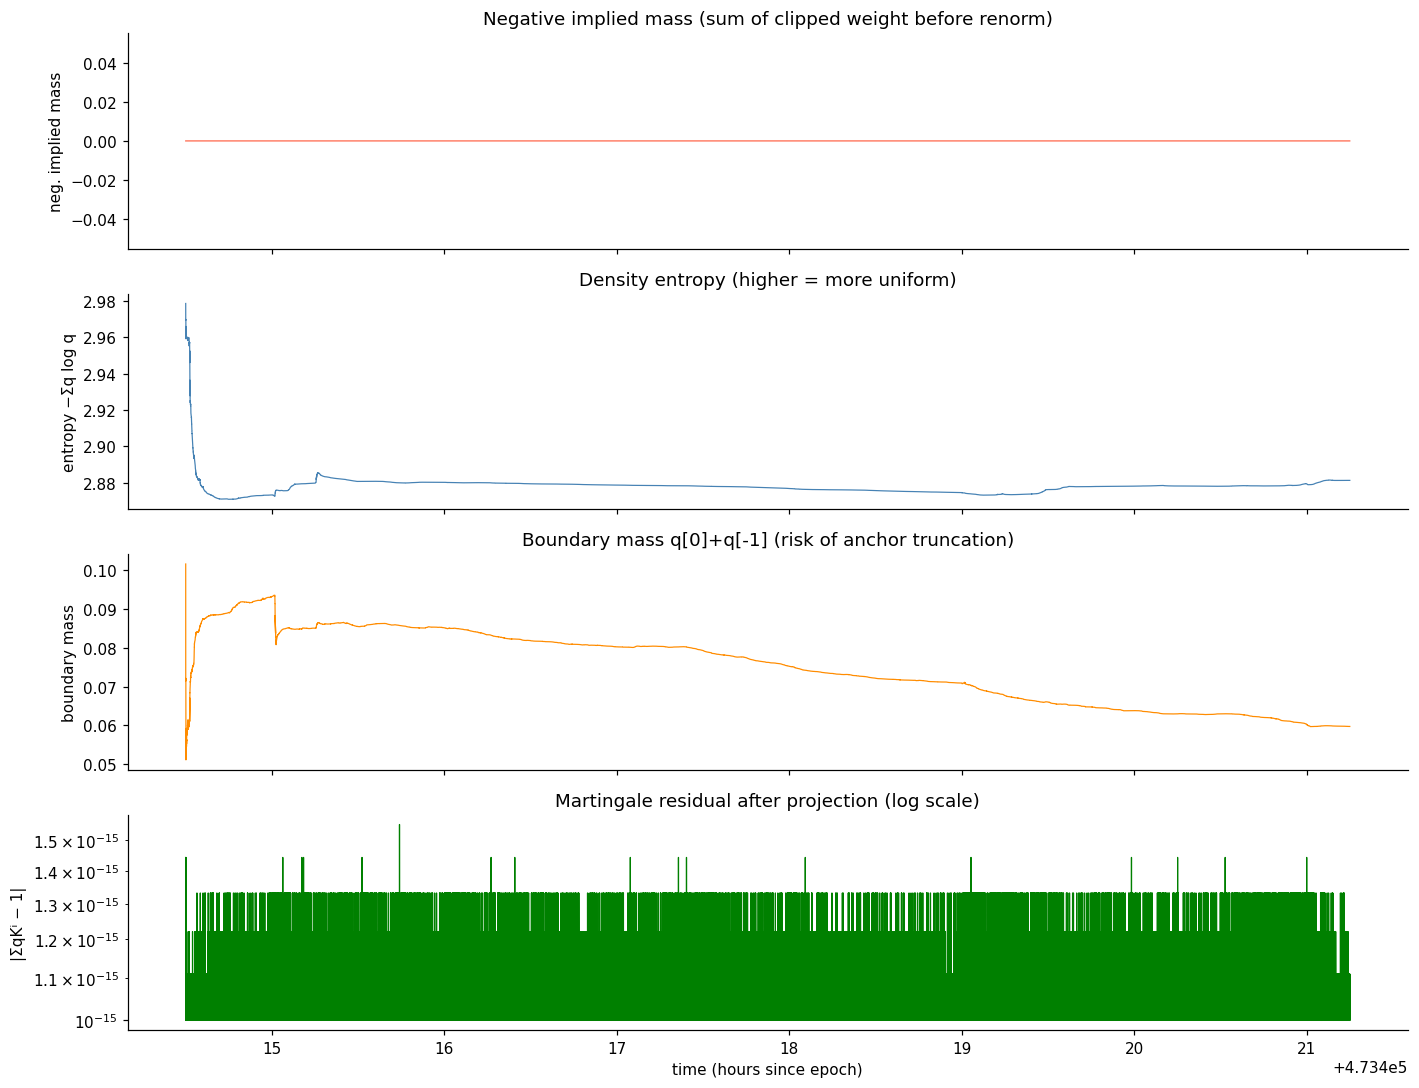

In [138]:
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)

axes[0].plot(ts_state, neg_mass, color="tomato", lw=0.8)
axes[0].set_ylabel("neg. implied mass")
axes[0].set_title("Negative implied mass (sum of clipped weight before renorm)")

axes[1].plot(ts_state, entropy, color="steelblue", lw=0.8)
axes[1].set_ylabel("entropy −Σq log q")
axes[1].set_title("Density entropy (higher = more uniform)")

axes[2].plot(ts_state, bdy_mass, color="darkorange", lw=0.8)
axes[2].set_ylabel("boundary mass")
axes[2].set_title("Boundary mass q[0]+q[-1] (risk of anchor truncation)")

axes[3].semilogy(ts_state, np.maximum(mart_resid, 1e-15), color="green", lw=0.8)
axes[3].set_ylabel("|ΣqKⁱ − 1|")
axes[3].set_xlabel("time (hours since epoch)")
axes[3].set_title("Martingale residual after projection (log scale)")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### 3e. Density snapshots at 3 intraday timestamps

In [139]:
anchor_ks

array([-0.03776687, -0.01090206, -0.00948179, -0.00825281, -0.00720416,
       -0.00617316, -0.00510253, -0.00385662, -0.00247566, -0.00129703,
        0.00012366,  0.00162015,  0.00320219,  0.00502317,  0.0072201 ,
        0.00913148,  0.01087306,  0.01294051,  0.01584665,  0.02409238])

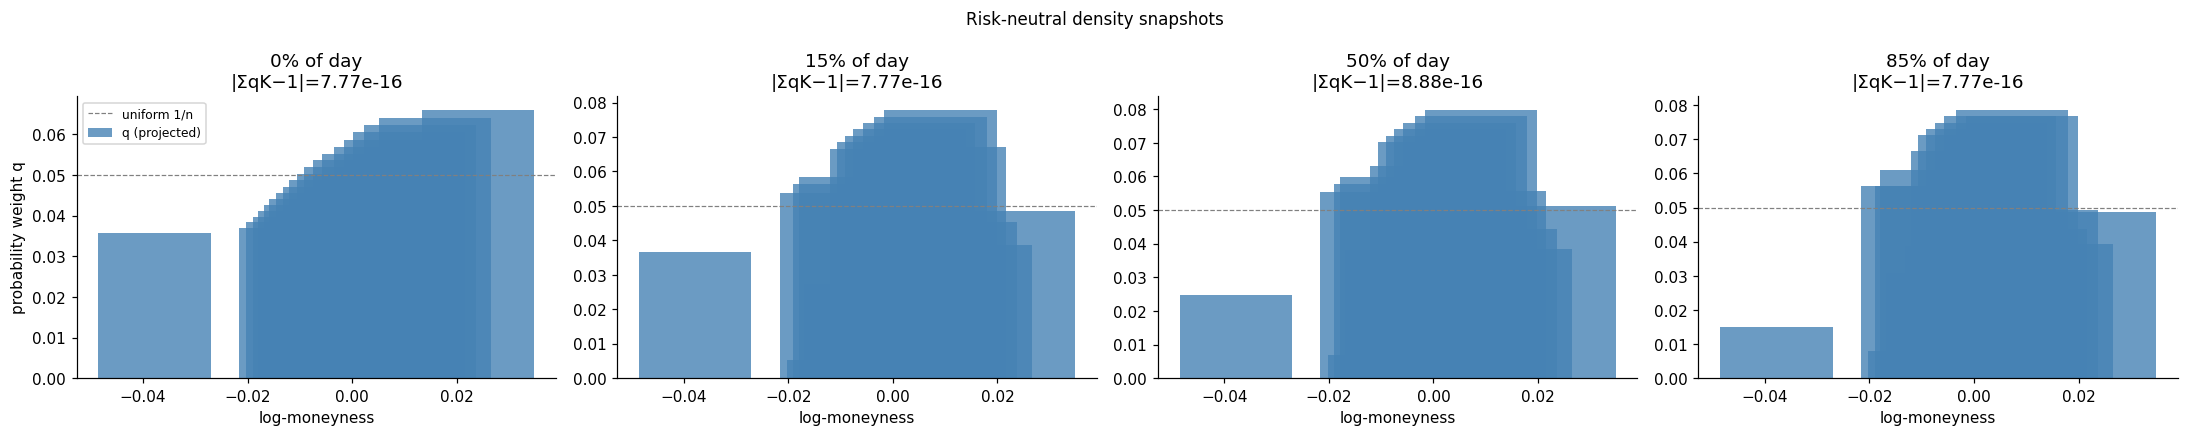

In [140]:
state_ts = df_state["ts_ns"].to_numpy()
valid_mask = np.isfinite(neg_mass)

snap_fracs = [0.00, 0.15, 0.50, 0.85]
snap_idxs = [np.where(valid_mask)[0][int(p * valid_mask.sum())] for p in snap_fracs]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, idx, frac in zip(axes, snap_idxs, snap_fracs):
    q = Q_arr[idx]
    ax.bar(
        anchor_ks,
        q,
        width=(anchor_ks[1] - anchor_ks[0]) * 0.8,
        color="steelblue",
        alpha=0.8,
        label="q (projected)",
    )
    ax.axhline(1 / n_a, color="gray", ls="--", lw=0.8, label="uniform 1/n")
    mart = np.dot(q, anchor_K)
    ax.set_title(f"{frac:.0%} of day\n|ΣqK−1|={abs(mart - 1):.2e}")
    ax.set_xlabel("log-moneyness")
    if ax is axes[0]:
        ax.set_ylabel("probability weight q")
        ax.legend(fontsize=8)

fig.suptitle("Risk-neutral density snapshots", fontsize=11)
plt.tight_layout()
plt.show()

---
## Section 4 — State Evolution

### 4a. σ* over time

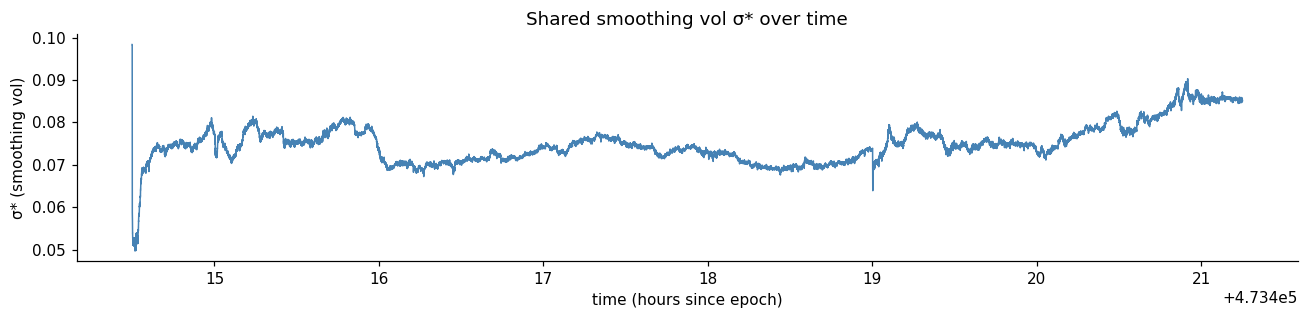

In [141]:
sigma_star = np.exp(X[:, n_a])  # last state component

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(ts_state, sigma_star, color="steelblue", lw=1.0)
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("σ* (smoothing vol)")
ax.set_title("Shared smoothing vol σ* over time")
plt.tight_layout()
plt.show()

### 4b. DLV heatmap (anchor × time)

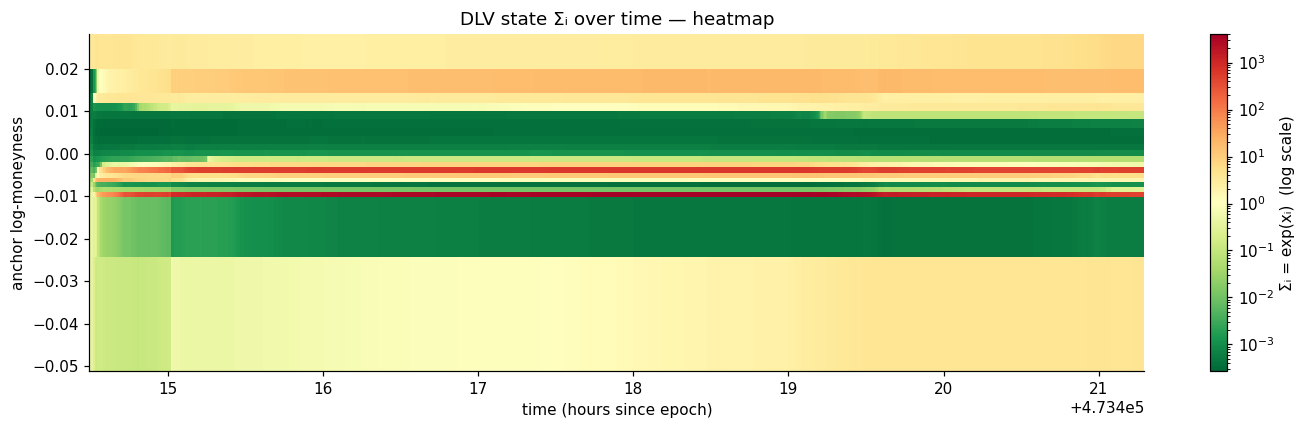

In [142]:
# Σᵢ = exp(x_i) for i=0…n-1; subsample to at most 500 time points for clarity
n_pts = len(X)
stride = max(1, n_pts // 500)
X_sub = X[::stride, :n_a]
ts_sub = ts_state[::stride]

Sigma_grid = np.exp(X_sub).T  # (n_a, n_time)

fig, ax = plt.subplots(figsize=(13, 4))
im = ax.pcolormesh(
    ts_sub,
    anchor_ks,
    Sigma_grid,
    cmap="RdYlGn_r",
    norm=mcolors.LogNorm(vmin=max(Sigma_grid.min(), 1e-4), vmax=Sigma_grid.max()),
)
plt.colorbar(im, ax=ax, label="Σᵢ = exp(xᵢ)  (log scale)")
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("anchor log-moneyness")
ax.set_title("DLV state Σᵢ over time — heatmap")
plt.tight_layout()
plt.show()

### 4c. Density weight q heatmap (anchor × time)

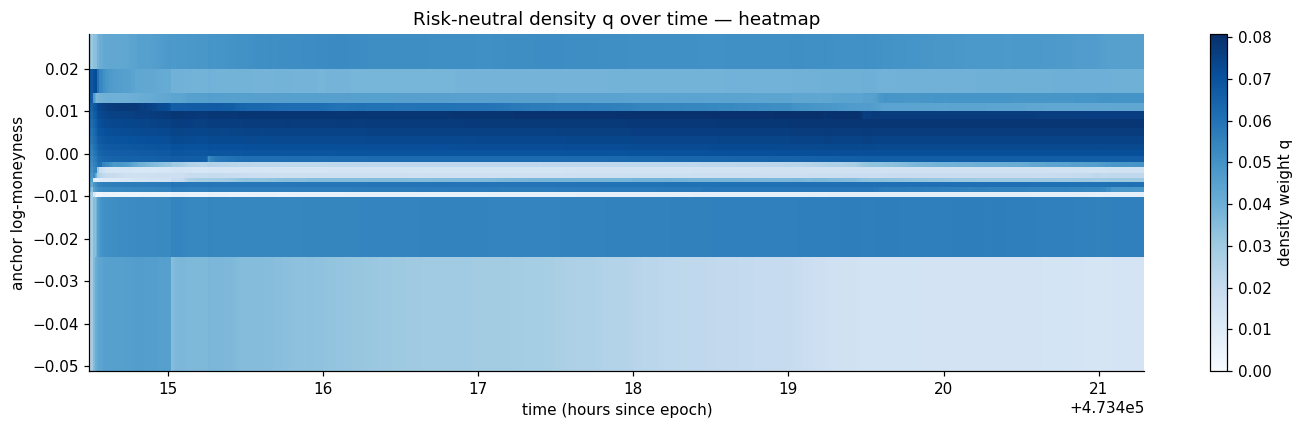

In [143]:
Q_sub = Q_arr[::stride].T  # (n_a, n_time)

fig, ax = plt.subplots(figsize=(13, 4))
im2 = ax.pcolormesh(ts_sub, anchor_ks, Q_sub, cmap="Blues", vmin=0)
plt.colorbar(im2, ax=ax, label="density weight q")
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("anchor log-moneyness")
ax.set_title("Risk-neutral density q over time — heatmap")
plt.tight_layout()
plt.show()